# Target Variable Analysis

## Objective
To understand the target variable, analyze its distribution, calculate summary statistics, and identify patterns important for machine learning.

## Dataset
ml_training_data.csv

## Target Variable
Exam_Marks

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn


## 1. What is a Target Variable?

A target variable is the variable that a machine learning model tries to predict.

Target variables can be:

- **Classification target:** Represents categories, such as Pass or Fail.
- **Regression target:** Represents numerical values, such as exam marks or house prices.

In this notebook, we will analyze Exam_Marks as a regression target.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


In [2]:
import os

file_paths = [
    "ml_training_data.csv",
    r"C:\Users\giris\ml_training_data.csv",
    r"C:\Users\giris\OneDrive\Desktop\sprint-4\ml_training_data.csv"
]

file_path = next((p for p in file_paths if os.path.exists(p)), None)

if file_path is None:
    raise FileNotFoundError(
        "Dataset not found. Check the location of ml_training_data.csv."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (5, 3)


,Study_Hours,Attendance,Exam_Marks
0,2,60,50
1,3,65,55
2,4,75,65
3,5,85,75
4,6,95,90


## 2. Identify the Target Variable

The target variable is the column we want to predict.

We will use Exam_Marks as the target because it represents a numerical outcome.


In [3]:
target_column = "Exam_Marks"

if target_column not in df.columns:
    raise ValueError(
        f"{target_column} was not found. Available columns: {df.columns.tolist()}"
    )

target = df[target_column]

print("Target variable:", target_column)
print("Data type:", target.dtype)
print("Number of records:", len(target))
print("Missing target values:", target.isnull().sum())

display(target.head())


Target variable: Exam_Marks
Data type: int64
Number of records: 5
Missing target values: 0


0    50
1    55
2    65
3    75
4    90
Name: Exam_Marks, dtype: int64

## 3. Target Variable Summary Statistics

Summary statistics help us understand the target variable's central value, spread, and range.


In [4]:
display(target.describe().to_frame(name="Exam_Marks Statistics"))

,Exam_Marks Statistics
count,5.000000
mean,67.000000
std,16.046807
min,50.000000
25%,55.000000
50%,65.000000
75%,75.000000
max,90.000000


## 4. Target Variable Distribution

A histogram shows how the target values are distributed.

It helps us identify where most exam marks are concentrated and whether the distribution is spread out or skewed.


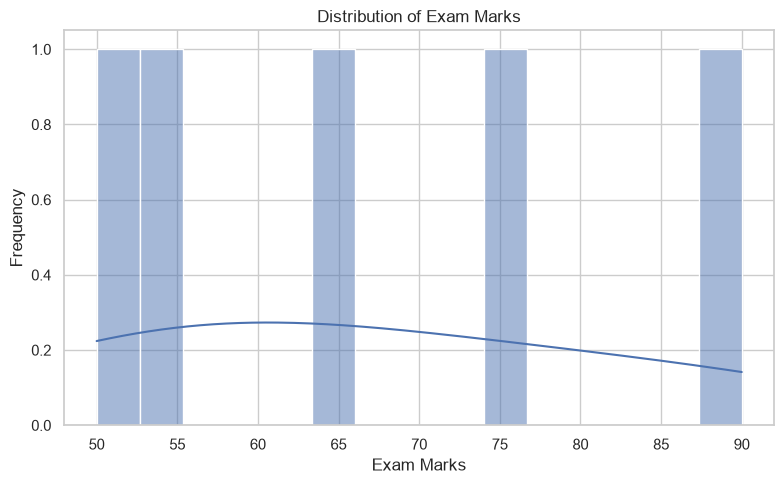

In [5]:
target_numeric = pd.to_numeric(target, errors="coerce").dropna()

if target_numeric.empty:
    print("No valid numerical target values are available.")
else:
    plt.figure(figsize=(8, 5))
    sns.histplot(target_numeric, bins=15, kde=True)
    plt.title("Distribution of Exam Marks")
    plt.xlabel("Exam Marks")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


## 5. Mean and Median of the Target

The mean is the average of all target values. The median is the middle value when the values are sorted.

Comparing them helps us understand the center of the target distribution.


In [6]:
if target_numeric.empty:
    print("Mean and median cannot be calculated.")
else:
    print("Mean:", round(target_numeric.mean(), 2))
    print("Median:", round(target_numeric.median(), 2))
    print("Standard deviation:", round(target_numeric.std(), 2))
    print("Minimum:", target_numeric.min())
    print("Maximum:", target_numeric.max())


Mean: 67.0
Median: 65.0
Standard deviation: 16.05
Minimum: 50
Maximum: 90


## 6. Target Skewness and Kurtosis

Skewness measures the asymmetry of the target distribution.

Kurtosis describes aspects of the distribution's tail heaviness. Pandas reports excess kurtosis.

These statistics help us understand the shape of the target distribution.


In [7]:
if len(target_numeric) >= 3:
    print("Skewness:", round(target_numeric.skew(), 3))
    print("Excess kurtosis:", round(target_numeric.kurt(), 3))
else:
    print("More valid target values are needed for reliable shape analysis.")


Skewness: 0.608
Excess kurtosis: -0.681


## 7. Check for Missing Target Values

Missing target values are important because supervised machine learning models generally require a known target during training.

We will count the missing target values before model development.


In [8]:
missing_count = target.isnull().sum()
missing_percentage = (missing_count / len(df) * 100) if len(df) else 0

print("Missing target values:", missing_count)
print("Missing target percentage:", round(missing_percentage, 2), "%")


Missing target values: 0
Missing target percentage: 0.0 %



## 8. Classification vs Regression

Classification predicts categories, such as Pass or Fail.

Regression predicts numerical values, such as exam marks.

Exam_Marks is treated as a regression target in this notebook because it contains numerical values. We should not convert it into categories unless a classification task specifically requires it.


In [9]:

print("Target column:", target_column)

if pd.api.types.is_numeric_dtype(target):
    print("Target type: Numerical")
    print("Suggested task: Regression")
else:
    print("Target type: Non-numerical")
    print("Suggested task: Classification, after checking the meaning of its values.")


Target column: Exam_Marks
Target type: Numerical
Suggested task: Regression


## 9. Observations and Insights

- Analyzed the target variable using summary statistics and visualizations.
- Examined the mean, median, standard deviation, minimum, and maximum.
- Used a histogram to understand the distribution of exam marks.
- Checked skewness and kurtosis to understand the shape of the distribution.
- Checked for missing target values that may affect model training.
- Identified Exam_Marks as a regression target because it represents numerical marks.

The exact findings about the distribution should be based on the outputs produced by the notebook.


## 10. Importance in Machine Learning

Target variable analysis is important because it helps us:

- Understand what the model needs to predict.
- Detect missing target values.
- Understand the range and spread of target values.
- Identify unusual distribution patterns.
- Choose an appropriate evaluation approach for the prediction task.

For regression, metrics such as MAE, MSE, RMSE, and R-squared can be used later to evaluate model performance.
